# M&A Deal Analyzer: Microsoft / Activision Blizzard

**Author:** Manuel Ferreira

**Question:** Was the price Microsoft paid for Activision Blizzard defensible against simple market benchmarks, and how did the market and Microsoft's EPS respond?

On 18 January 2022 Microsoft announced an all-cash offer of USD 95.00 per share, valued at USD 68.7bn inclusive of Activision's net cash. The deal closed on 13 October 2023.

**This is a retrospective analysis.** It combines market prices from around the announcement with financial statements for nearby periods, some of which were published later. It does not reconstruct what an investor could have known on 18 January 2022.

| Data | Date or period | Published |
|---|---|---|
| Activision, Microsoft and index prices | Around 18 January 2022 | Market data |
| Peer share prices | EA: 12 Jan 2022; Take-Two: 14 Jan 2022 | Market data |
| Activision financials | Year to December 2021 | February 2022, after the announcement |
| Microsoft financials | Year to June 2021 | July 2021, before the announcement |
| Peer financials | Years to March 2022 | May 2022, after the announcement |
| Deal outcome and Microsoft's later results | October 2023 onwards | Used only as a later comparison |

Every input, with its period, publication date and source, is in `data/inputs.csv`. Daily prices are not in this repository: the saved outputs show the results, and `data/README.md` explains how to supply your own data to re-run the market sections. Figures are in USD millions unless stated.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

sys.path.insert(0, "src")
import deal_model as dm
from price_data import load_market_prices

I = dm.load_inputs("data/inputs.csv")

# Daily prices are not in this repository. Sections 3 and the summary need them.
MARKET_DATA = Path("data/market_prices.csv").exists()
if MARKET_DATA:
    prices = load_market_prices("data/market_prices.csv")
    print(f"FULL RUN: market data loaded, {len(prices)} observations.")
else:
    prices = None
    print("PARTIAL RUN: data/market_prices.csv is missing, so market sections will be skipped. "
          "See data/README.md to import it.")

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 150, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
CHARTS = Path(os.environ.get("CHARTS_DIR", "charts"))
CHARTS.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

FULL RUN: market data loaded, 159 observations.


## 1. Price paid

The headline USD 68.7bn is an **enterprise value**. Shareholders received more, because Microsoft also acquired Activision's net cash.

The diluted share count behind the headline is not disclosed in the announcement, so it is **estimated** by working backwards, assuming the headline used Activision's cash and debt at 31 December 2021. Recreating USD 68.7bn from this estimate would be circular, so I test it in two independent ways:

1. A bottom-up estimate from the 2021 Form 10-K: shares outstanding, plus RSUs at target, plus options under the treasury stock method at USD 95, using their average exercise price.
2. A plausibility check against the purchase price Microsoft reported at closing. This is not a full reconciliation, because it is 21 months later and may include different components.

I could not find a complete public bridge between awards, consideration and net cash at a single date, so a small gap is left unexplained.

In [2]:
offer = I["offer_price"]
net_cash = I["atvi_cash"] - I["atvi_debt"]
shares = dm.implied_diluted_shares(I["deal_value"], I["atvi_cash"], I["atvi_debt"], offer)
equity_paid = shares * offer
premium_paid = (offer - I["atvi_undisturbed"]) * shares

basic = I["atvi_shares_issued"] - I["atvi_treasury_shares"]
bottom_up = dm.treasury_method_shares(basic, I["atvi_rsus"], I["atvi_options"], I["atvi_option_strike"], offer)

print("Share counts (millions)")
print(f"  Outstanding, 31 Dec 2021:              {basic:8.1f}")
print(f"  Outstanding, 18 Feb 2022:              {I['atvi_shares_feb22']:8.1f}")
print(f"  Outstanding, 14 Mar 2022:              {I['atvi_shares_record_date']:8.1f}")
print(f"  Weighted average diluted, FY2021 EPS:  {I['atvi_weighted_diluted']:8.1f}")
print(f"  Bottom-up at $95, RSUs at target,\n  options at average strike:             {bottom_up:8.1f}")
print(f"  Estimate implied by the headline:      {shares:8.1f}  (gap to bottom-up {shares / bottom_up - 1:+.2%})")
print()
print(f"Net cash used, 31 Dec 2021:              ${net_cash:,.0f}m")
print(f"Estimated equity purchase price:         ${equity_paid:,.0f}m")
print(f"Purchase price reported at closing:      ${I['close_purchase_price']:,.0f}m  (gap {equity_paid / I['close_purchase_price'] - 1:+.2%})")
print(f"Net cash at closing (cash less debt):    ${I['close_cash'] - I['close_debt']:,.0f}m")
print()
print(f"Premium to 14 Jan 2022 close:            {dm.premium(offer, I['atvi_undisturbed']):.1%}  (proxy: {I['premium_1d_proxy']:.1%})")
print(f"Premium to 30-day VWAP (proxy):          {I['premium_30d_vwap']:.1%}")
print(f"Premium to Dec 2021 low close:           {dm.premium(offer, I['atvi_low_close']):.1%}")
print(f"Premium in dollars, estimated:           ${premium_paid:,.0f}m")

Share counts (millions)
  Outstanding, 31 Dec 2021:                 779.1
  Outstanding, 18 Feb 2022:                 779.2
  Outstanding, 14 Mar 2022:                 780.9
  Weighted average diluted, FY2021 EPS:     784.0
  Bottom-up at $95, RSUs at target,
  options at average strike:                795.9
  Estimate implied by the headline:         794.9  (gap to bottom-up -0.13%)

Net cash used, 31 Dec 2021:              $6,815m
Estimated equity purchase price:         $75,515m
Purchase price reported at closing:      $75,406m  (gap +0.14%)
Net cash at closing (cash less debt):    $10,177m

Premium to 14 Jan 2022 close:            45.3%  (proxy: 45.3%)
Premium to 30-day VWAP (proxy):          50.3%
Premium to Dec 2021 low close:           65.9%
Premium in dollars, estimated:           $23,537m


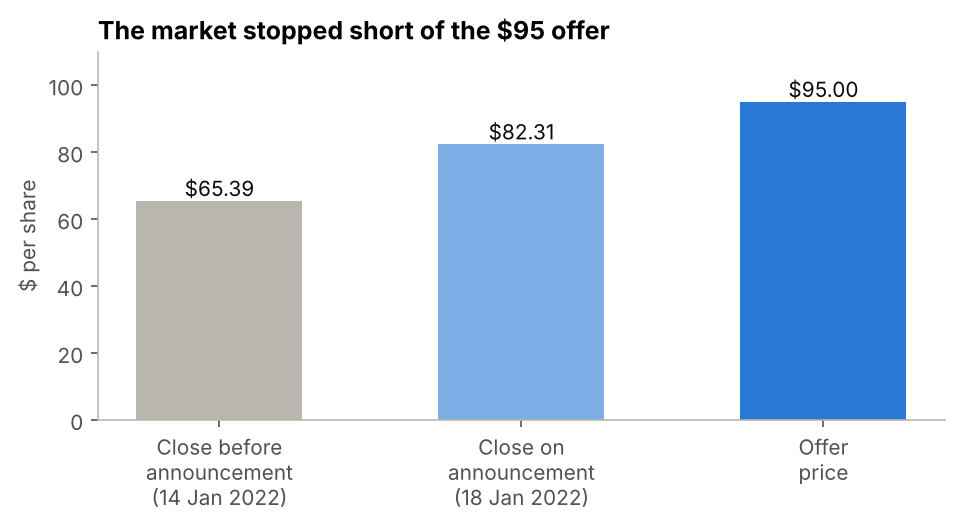

In [3]:
labels = ["Close before\nannouncement\n(14 Jan 2022)", "Close on\nannouncement\n(18 Jan 2022)", "Offer\nprice"]
values = [I["atvi_undisturbed"], I["atvi_day1_close"], offer]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(labels, values, color=[GREY, BLUE, BLUE], width=0.55)
bars[1].set_alpha(0.6)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"${value:.2f}", ha="center", color=INK)
ax.set_ylim(0, 110)
ax.set_ylabel("$ per share")
ax.set_title("The market stopped short of the $95 offer")
save(fig, "1_price_gap")

## 2. Valuation against peers

Multiples for Activision are shown twice: at the offer price, and at the price before the announcement. Electronic Arts and Take-Two are the closest listed peers.

### EBITDA policy

Game companies capitalize different amounts of development spending, so EBITDA needs a stated definition.

**Policy used:** Adjusted EBITDA = EBIT + depreciation + amortization and impairment of acquired intangibles. This is a project definition, not a reported figure or a standard measure, because it adds back impairment and leaves out certain software amortization. Amortization of capitalized software and licenses is **not** added back, because it represents the cost of making games. EA expenses almost all of that cost, so adding it back for the others would flatter them relative to EA.

**Alternative shown:** the same measure plus amortization and impairment of capitalized software and licenses, as far as each company reports it.

| Item | Activision | EA | Take-Two |
|---|---|---|---|
| Depreciation and acquired intangibles | Single USD 116m line, including USD 10m of intangibles | USD 162m + USD 316m, including USD 45m of impairment | USD 61.2m + USD 62.9m from the non-GAAP reconciliation |
| Capitalized software and licenses | USD 324m, added only in the alternative | Described as insignificant | USD 153.3m + USD 70.6m impairment, added only in the alternative |
| Not used | | USD 8m difference to EA's USD 486m cash flow line, which also includes accretion | USD 64.8m IP amortization replaces the USD 62.9m in the alternative, to avoid double counting |

**Differences that remain:** the items are reported on different bases, the amount of Take-Two's IP amortization that overlaps with acquired intangibles is not fully disclosed, and each company has different capitalization policies. I therefore give EV/Adjusted EBITDA little weight in the conclusions.

In [4]:
addbacks = {
    "atvi": I["atvi_da"],
    "ea": I["ea_depreciation"] + I["ea_intangibles"],
    "ttwo": I["ttwo_depreciation"] + I["ttwo_intangibles"],
}
addbacks_alt = {
    "atvi": I["atvi_da"] + I["atvi_capsw"],
    "ea": I["ea_depreciation"] + I["ea_intangibles"] + I["ea_capsw"],
    "ttwo": I["ttwo_depreciation"] + I["ttwo_ip_amort"] + I["ttwo_capsw"] + I["ttwo_capsw_impairment"],
}

def peer(prefix, price=None, share_count=None, adds=addbacks):
    return dm.valuation_multiples(
        price if price is not None else I[f"{prefix}_price"],
        share_count if share_count is not None else I[f"{prefix}_shares"],
        I[f"{prefix}_cash"], I[f"{prefix}_debt"], I[f"{prefix}_revenue"],
        I[f"{prefix}_ebit"], adds[prefix], I[f"{prefix}_net_income"])

comps = pd.DataFrame({
    "ATVI at $95": peer("atvi", offer, shares),
    "ATVI before deal": peer("atvi", I["atvi_undisturbed"], shares),
    "EA": peer("ea"),
    "Take-Two": peer("ttwo"),
})
print(comps.rename(index={"EV/EBITDA": "EV/Adjusted EBITDA"}).round(3).to_string())

reconciliation = pd.DataFrame({
    "Activision": [I["atvi_ebit"], addbacks["atvi"], I["atvi_ebit"] + addbacks["atvi"], I["atvi_ebit"] + addbacks_alt["atvi"]],
    "EA": [I["ea_ebit"], addbacks["ea"], I["ea_ebit"] + addbacks["ea"], I["ea_ebit"] + addbacks_alt["ea"]],
    "Take-Two": [I["ttwo_ebit"], addbacks["ttwo"], I["ttwo_ebit"] + addbacks["ttwo"], I["ttwo_ebit"] + addbacks_alt["ttwo"]],
}, index=["EBIT", "Add-backs under the policy", "Adjusted EBITDA, policy", "Adjusted EBITDA, alternative"])
print("\nEBIT to Adjusted EBITDA ($m)")
print(reconciliation.round(1).to_string())

alternative = pd.Series({
    "ATVI at $95": peer("atvi", offer, shares, addbacks_alt)["EV/EBITDA"],
    "EA": peer("ea", adds=addbacks_alt)["EV/EBITDA"],
    "Take-Two": peer("ttwo", adds=addbacks_alt)["EV/EBITDA"],
})
print("\nEV/Adjusted EBITDA under the alternative")
print(alternative.round(1).to_string())

ea_cover = peer("ea", share_count=I["ea_shares_cover"])
print(f"\nEA EV/Revenue with {I['ea_shares_cover']:.1f}m shares outstanding (May 2022) instead of "
      f"{I['ea_shares']:.0f}m weighted diluted: {ea_cover['EV/Revenue']:.1f}x")

                    ATVI at $95  ATVI before deal      EA  Take-Two
Equity value ($bn)       75.515            51.978  37.895    17.821
EV ($bn)                 68.700            45.163  36.711    15.269
EV/Revenue                7.804             5.130   5.251     4.357
EV/Adjusted EBITDA       20.356            13.382  22.844    25.549
P/E                      27.979            19.258  48.029    42.635
EBIT margin               0.370             0.370   0.161     0.135

EBIT to Adjusted EBITDA ($m)
                              Activision      EA  Take-Two
EBIT                              3259.0  1129.0     473.6
Add-backs under the policy         116.0   478.0     124.1
Adjusted EBITDA, policy           3375.0  1607.0     597.7
Adjusted EBITDA, alternative      3699.0  1607.0     823.5

EV/Adjusted EBITDA under the alternative
ATVI at $95    18.6
EA             22.8
Take-Two       18.5

EA EV/Revenue with 279.9m shares outstanding (May 2022) instead of 286m weighted diluted: 5.1x


**Limits of this comparison**
- Only two peers, so this is a sense-check rather than a valuation.
- Peer financials are for years ending March 2022, and prices are from January 2022, so price and earnings dates do not match.
- Peer equity values use weighted average diluted shares for the year, not a count at the pricing date.
- Activision's multiples before the deal use the same share estimate as at USD 95. Options would add fewer shares at a lower price, so this slightly overstates them.
- Take-Two had announced its Zynga deal on 10 January 2022, which may affect its price.
- Figures are GAAP, and deferred revenue affects all three companies differently.

EBIT margin
ATVI at $95    37.0%
EA             16.1%
Take-Two       13.5%


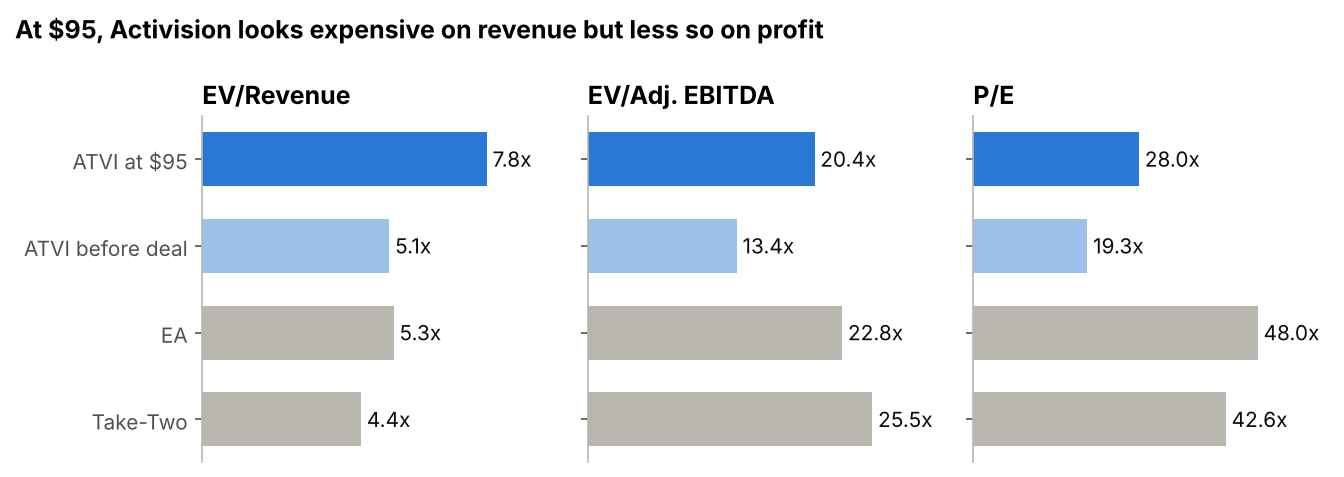

In [5]:
metrics = ["EV/Revenue", "EV/EBITDA", "P/E"]
order = ["ATVI at $95", "ATVI before deal", "EA", "Take-Two"]
colours = [BLUE, "#9dc0ea", GREY, GREY]

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, metric in zip(axes, metrics):
    series = comps.loc[metric, order]
    ax.barh(order[::-1], series[::-1], color=colours[::-1], height=0.62)
    for y, value in enumerate(series[::-1]):
        ax.text(value + series.max() * 0.02, y, f"{value:.1f}x", va="center", color=INK)
    ax.set_title(metric.replace("EBITDA", "Adj. EBITDA"))
    ax.set_xlim(0, series.max() * 1.25)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("At $95, Activision looks expensive on revenue but less so on profit",
             x=0.01, ha="left", fontweight="bold")
save(fig, "2_multiples")

print("EBIT margin")
print(comps.loc["EBIT margin", ["ATVI at $95", "EA", "Take-Two"]].map("{:.1%}".format).to_string())

## 3. Market reaction

### Microsoft: event study

An event study asks how much of a share price move cannot be explained by the wider market. I fit a market model on 120 trading days ending 10 days before the announcement, then compare actual returns with what the model predicted:

$$R_{MSFT} = \alpha + \beta R_{benchmark} + \varepsilon$$

**Method**
- **Returns:** Microsoft's returns use Yahoo's dividend-adjusted close. The main benchmark is the S&P 500 total return index, so dividends are treated consistently on both sides. The S&P 500 price index and the Nasdaq-100 price index are shown as checks. Microsoft is a large part of these indices, which slightly reduces any measured abnormal return.
- **Standard errors:** these include the uncertainty in the fitted alpha and beta. They assume independent, normally distributed residuals with constant variance. A t-statistic beyond about ±2 is the usual threshold for significance.
- **Timing:** the market was closed on 17 January, and the deal was announced before the open on 18 January, so 18 January is day 0.

**What is shown:** the tables show model results, not the underlying daily prices or returns.

**Other events in the window**
- **18 January:** news reports attributed the market's fall to rising Treasury yields hitting large technology stocks and to Goldman Sachs' earnings miss. The market model removes only the part of this captured by the benchmark and beta.
- **13 January (day -2):** Microsoft's abnormal return was large. It came before the announcement and I have not investigated its cause.
- **25 January (day +5):** Microsoft reported earnings after the close, so the reaction falls on day +6, outside the window.

An abnormal return is therefore not a causal estimate of the deal's effect on value.

In [6]:
if MARKET_DATA:
    returns = prices["msft_adj_close"].pct_change()
    benchmarks = {"S&P 500 total return (main)": "sp500tr_close", "S&P 500 price": "sp500_close", "Nasdaq-100 price": "ndx_close"}
    studies = {name: dm.market_model_event_study(returns, prices[col].pct_change(), "2022-01-18")
               for name, col in benchmarks.items()}
    study = studies["S&P 500 total return (main)"]

    print(f"Main model: alpha {study.alpha:.4%} | beta {study.beta:.2f} | R-squared {study.r_squared:.2f} | "
          f"residual st. dev. {study.residual_std:.2%} | n = {study.observations}")
    print()
    print(study.table.set_index("day")[["abnormal", "std_error", "t_stat"]].round(4).to_string())
    print()

    rows = {}
    for name, s in studies.items():
        row = {"Beta": s.beta, "R-squared": s.r_squared}
        for first, last in [(0, 0), (-1, 1), (-5, 5)]:
            car, t = dm.cumulative_abnormal(s, first, last)
            row[f"CAR [{first:+d},{last:+d}]"] = f"{car:+.2%}"
            row[f"t [{first:+d},{last:+d}]"] = round(t, 2)
        rows[name] = row
    print(pd.DataFrame(rows).T.round(2).to_string())

    msft_cap = prices.loc["2022-01-14", "msft_close"] * I["msft_diluted_shares"]
    day0, t0 = dm.cumulative_abnormal(study, 0, 0)
    print(f"\\nDay-0 abnormal move on a market value of about ${msft_cap / 1000:,.0f}bn "
          f"(FY2021 weighted diluted shares): {'-' if day0 < 0 else '+'}${abs(day0) * msft_cap / 1000:,.1f}bn")
else:
    print("SKIPPED: the event study needs data/market_prices.csv.")

Main model: alpha 0.0672% | beta 1.16 | R-squared 0.54 | residual st. dev. 0.86% | n = 120

     abnormal  std_error  t_stat
day                             
-5     0.0017     0.0087  0.1998
-4    -0.0090     0.0087 -1.0375
-3     0.0065     0.0087  0.7508
-2    -0.0266     0.0088 -3.0368
-1     0.0161     0.0086  1.8589
0     -0.0037     0.0089 -0.4236
1      0.0128     0.0087  1.4658
2      0.0063     0.0087  0.7235
3      0.0027     0.0089  0.3089
4     -0.0027     0.0087 -0.3157
5     -0.0132     0.0087 -1.5077

                                 Beta R-squared CAR [+0,+0] t [+0,+0] CAR [-1,+1] t [-1,+1] CAR [-5,+5] t [-5,+5]
S&P 500 total return (main)  1.157288  0.541511      -0.37%     -0.42      +2.51%      1.63      -0.92%      -0.3
S&P 500 price                1.157501  0.542312      -0.38%     -0.43      +2.50%      1.63      -0.96%     -0.31
Nasdaq-100 price             1.010609  0.666397      +0.08%      0.11      +2.25%      1.72      +0.50%      0.19
\nDay-0 abnormal move 

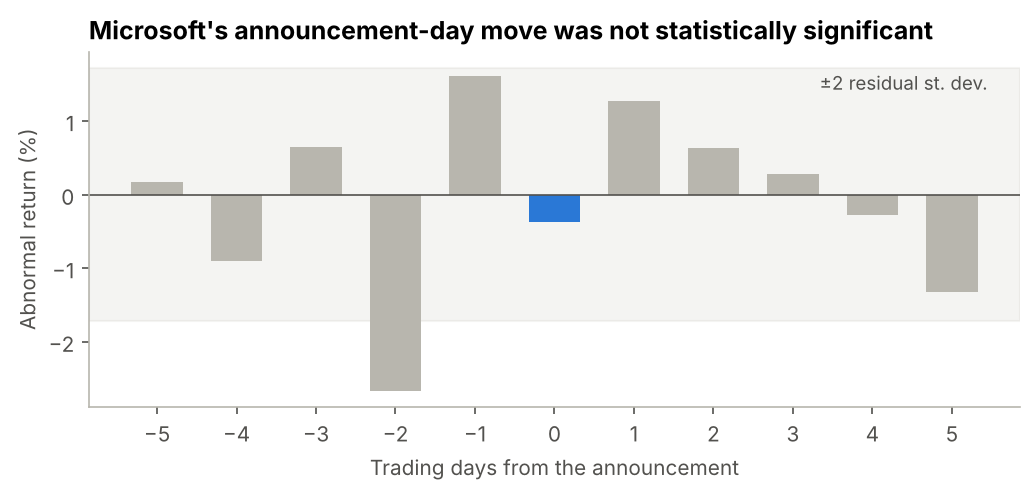

In [7]:
if MARKET_DATA:
    table = study.table
    fig, ax = plt.subplots(figsize=(7, 3.4))
    colors = [BLUE if d == 0 else GREY for d in table["day"]]
    ax.bar(table["day"], table["abnormal"] * 100, color=colors, width=0.65)
    band = 2 * study.residual_std * 100
    ax.axhspan(-band, band, color=GREY, alpha=0.15, zorder=0)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.text(5.45, band - 0.05, "±2 residual st. dev.", ha="right", va="top", color=MUTED, fontsize=9)
    ax.set_xticks(table["day"])
    ax.set_xlabel("Trading days from the announcement")
    ax.set_ylabel("Abnormal return (%)")
    ax.set_title("Microsoft's announcement-day move was not statistically significant")
    save(fig, "3_msft_event_study")
else:
    print("SKIPPED: this chart needs data/market_prices.csv.")

### Activision: market-adjusted return and deal spread

Yahoo Finance and Nasdaq no longer serve Activision's delisted ticker, so I could not fit the same daily model for it. A market-adjusted return (its price return minus the S&P 500 price return) is a simple substitute.

The gap between the share price and the offer can be read through a simplified binary model:

$$p = \frac{P_{market} - P_{fallback}}{P_{offer} - P_{fallback}}$$

**How to read the result:** this is a probability implied by a simplified model, conditional on the assumed fallback price, with no discounting or risk premium. It is not an objective probability of completion. The spread also compensates for the time until closing, which was expected to be in Microsoft's fiscal 2023 at announcement, and for the risk borne by arbitrage investors. The fallback price is itself uncertain, and a reverse termination fee of USD 2bn to USD 3bn was payable by Microsoft in specified circumstances.

In [8]:
atvi_return = I["atvi_day1_close"] / I["atvi_undisturbed"] - 1
spread = offer / I["atvi_day1_close"] - 1
gain_to_holders = (I["atvi_day1_close"] - I["atvi_undisturbed"]) * shares

print(f"ATVI price return on 18 Jan 2022:  {atvi_return:+.1%}")
if MARKET_DATA:
    index_return = prices["sp500_close"].pct_change().loc["2022-01-18"]
    print(f"S&P 500 price return:              {index_return:+.1%}")
    print(f"Market-adjusted return:            {atvi_return - index_return:+.1%}")
else:
    print("Market-adjusted return:            SKIPPED, needs data/market_prices.csv")
print(f"Estimated value gained by holders: ${gain_to_holders / 1000:.1f}bn")
print(f"Gross spread to $95:               {spread:.1%}")
print()
print("Implied probability in the binary model, by assumed fallback price")
for fallback in [55, 60, I["atvi_undisturbed"], 70]:
    p = dm.implied_completion_probability(I["atvi_day1_close"], offer, fallback)
    print(f"  ${fallback:>6.2f}: {p:.0%}")

ATVI price return on 18 Jan 2022:  +25.9%
S&P 500 price return:              -1.8%
Market-adjusted return:            +27.7%
Estimated value gained by holders: $13.4bn
Gross spread to $95:               15.4%

Implied probability in the binary model, by assumed fallback price
  $ 55.00: 68%
  $ 60.00: 64%
  $ 65.39: 57%
  $ 70.00: 49%


**With hindsight.** The figures below use the actual closing date, which was not known at announcement.

Buying at the day-1 close and holding to closing: 15.4% over 1.73 years = 8.6% a year, before dividends
S&P 500 price change over the same period:        -5.4%


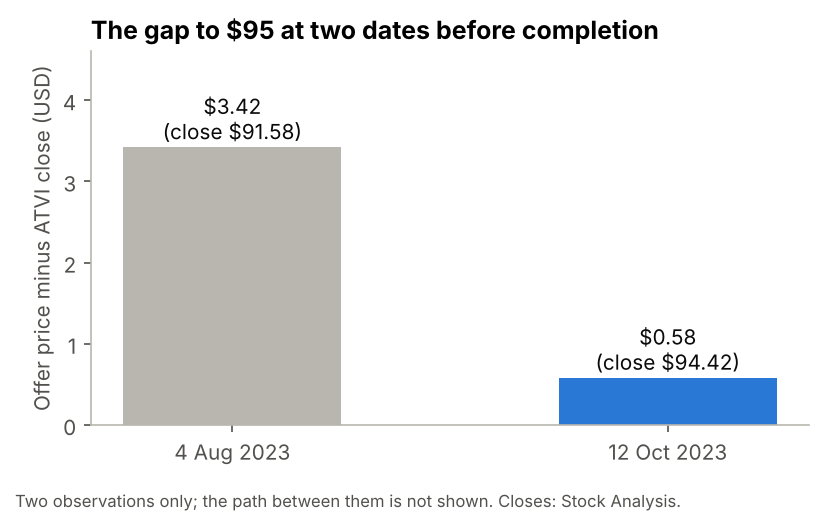

In [9]:
years = (pd.Timestamp("2023-10-13") - pd.Timestamp("2022-01-18")).days / 365.25
annualised = (offer / I["atvi_day1_close"]) ** (1 / years) - 1
print(f"Buying at the day-1 close and holding to closing: {spread:.1%} over {years:.2f} years "
      f"= {annualised:.1%} a year, before dividends")
if MARKET_DATA:
    sp_change = I["sp500_at_close"] / prices.loc["2022-01-18", "sp500_close"] - 1
    print(f"S&P 500 price change over the same period:        {sp_change:+.1%}")
else:
    print("S&P 500 price change over the same period:        SKIPPED, needs data/market_prices.csv")

gap_dates = ["4 Aug 2023", "12 Oct 2023"]
gaps = [offer - I["atvi_close_2023_08_04"], offer - I["atvi_close_2023_10_12"]]
closes = [I["atvi_close_2023_08_04"], I["atvi_close_2023_10_12"]]
fig, ax = plt.subplots(figsize=(5.5, 3.3))
bars = ax.bar(gap_dates, gaps, color=[GREY, BLUE], width=0.5)
for bar, value, close in zip(bars, gaps, closes):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.1, f"${value:.2f}\n(close ${close:.2f})",
            ha="center", color=INK)
ax.set_ylim(0, 4.6)
ax.set_ylabel("Offer price minus ATVI close (USD)")
ax.set_title("The gap to $95 at two dates before completion")
fig.text(0.01, -0.04, "Two observations only; the path between them is not shown. Closes: Stock Analysis.",
         color=MUTED, fontsize=8)
save(fig, "4_spread_2023")

## 4. Illustrative EPS impact

A deal is **accretive** if it raises the acquirer's earnings per share and **dilutive** if it lowers them. An all-cash deal issues no shares, so this simplified sensitivity asks whether the target's profits exceed the after-tax income lost on the cash spent:

$$EPS_{new} = \frac{NI_{MSFT} + NI_{ATVI} + (\text{Synergies} - \text{Amortization} - \text{Cash} \times y)(1-t)}{\text{MSFT shares}}$$

**This is not a test of value.** Higher EPS does not show that a deal creates value or that its price was fair. Assessing value creation would need forecast cash flows, a cost of capital and estimated synergies, which are outside the scope of this project.

**Assumptions I chose, which are not reported figures**
- `y`: a 1.0% pre-tax yield on Microsoft's cash, a judgement about early-2022 rates.
- `t`: 13.8%, Microsoft's FY2021 effective tax rate. It is used for all items as an approximation. Interest, synergies and amortization could in practice be taxed at different rates.
- Amortization: USD 2.5bn a year in the GAAP case. This is an illustrative **incremental** charge, on top of what is already in Activision's net income, not total post-deal amortization.
- Synergies: none in the base case.

**What the model leaves out**
- Integration and transaction costs, and purchase accounting adjustments other than amortization.
- Forecasts for the year of closing: it combines Microsoft's year to June 2021 with Activision's calendar 2021.
- Any share buybacks Microsoft might otherwise have made with the cash.

Activision's own cash is assumed to stay in the business, with its interest income remaining in its net income. **Within this model, the price paid affects EPS only through lost interest, so at a 0% yield the price has no effect at all.** That is a limit of EPS as a measure, not a finding about the price.

In [10]:
tax = I["msft_tax"] / I["msft_pretax_income"]
y_base = 0.01
amort_base = 2500
cash_used = equity_paid

msft_shares = I["msft_diluted_shares"]
rows = {
    "Non-GAAP, no synergies": (I["msft_net_income_nongaap"], I["atvi_net_income_nongaap"], 0),
    "GAAP, incremental amortization": (I["msft_net_income"], I["atvi_net_income"], amort_base),
}
result = {}
for name, (acq, tgt, amort) in rows.items():
    new_eps = dm.pro_forma_eps(acq, tgt, msft_shares, cash_used, y_base, tax, amortization=amort)
    result[name] = {
        "Standalone EPS": acq / msft_shares,
        "Pro forma EPS": new_eps,
        "EPS change": dm.accretion(acq, tgt, msft_shares, cash_used, y_base, tax, amortization=amort),
        "Breakeven yield": dm.breakeven_yield(tgt, cash_used, tax, amortization=amort),
    }
print(pd.DataFrame(result).round(4).to_string())
print(f"\nCash used as a share of Microsoft's June 2021 cash and short-term investments: {cash_used / I['msft_cash']:.0%}")

                 Non-GAAP, no synergies  GAAP, incremental amortization
Standalone EPS                   7.9720                          8.0535
Pro forma EPS                    8.3066                          8.0396
EPS change                       0.0420                         -0.0017
Breakeven yield                  0.0491                          0.0084

Cash used as a share of Microsoft's June 2021 cash and short-term investments: 58%


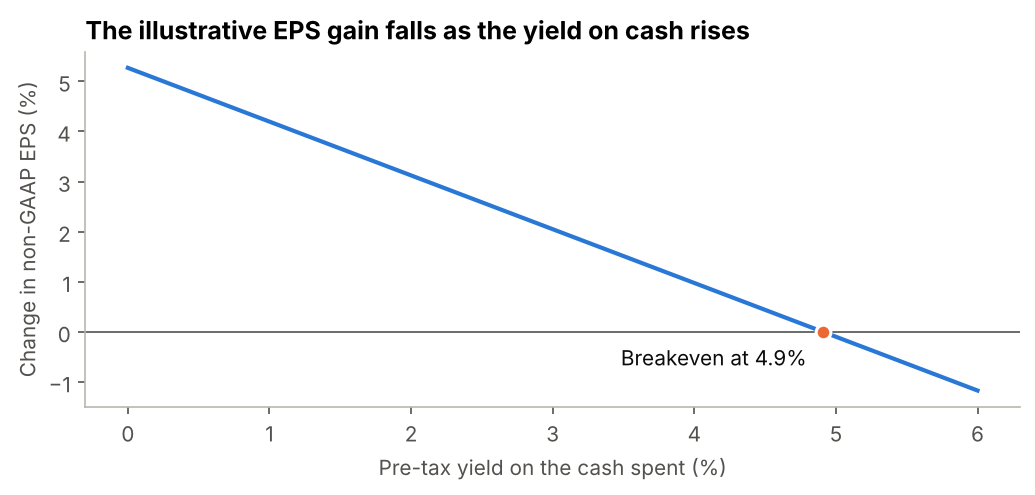

In [11]:
yields = np.linspace(0, 0.06, 61)
curve = [dm.accretion(I["msft_net_income_nongaap"], I["atvi_net_income_nongaap"], msft_shares, cash_used, y, tax) * 100
         for y in yields]
be = dm.breakeven_yield(I["atvi_net_income_nongaap"], cash_used, tax)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(yields * 100, curve, color=BLUE, linewidth=2)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.scatter([be * 100], [0], s=50, color=ORANGE, zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate(f"Breakeven at {be:.1%}", (be * 100, 0), xytext=(-8, -16), textcoords="offset points",
            ha="right", color=INK)
ax.set_xlabel("Pre-tax yield on the cash spent (%)")
ax.set_ylabel("Change in non-GAAP EPS (%)")
ax.set_title("The illustrative EPS gain falls as the yield on cash rises")
save(fig, "5_eps_vs_yield")

## 5. Sensitivities

Both tables change two assumptions at a time. Blue means higher EPS and orange means lower EPS. The size of any effect depends on the ranges chosen, and neither table says anything about value.

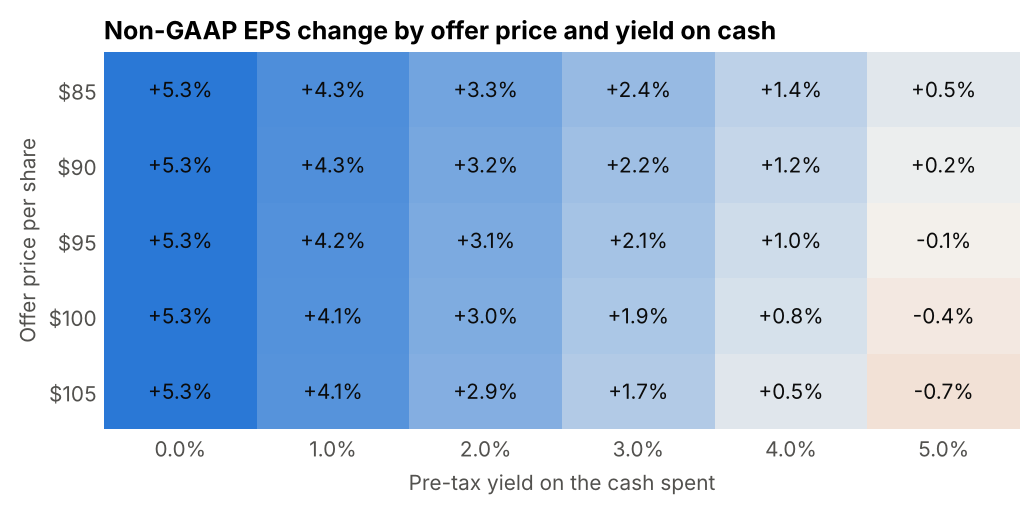

In [12]:
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f4f3ef", BLUE])

def heatmap(frame, title, xlabel, ylabel, name):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    limit = max(abs(frame.values.min()), abs(frame.values.max()), 0.1)
    ax.imshow(frame.values, cmap=cmap, norm=TwoSlopeNorm(0, -limit, limit), aspect="auto")
    ax.set_xticks(range(frame.shape[1]), frame.columns)
    ax.set_yticks(range(frame.shape[0]), frame.index)
    for (row, col), value in np.ndenumerate(frame.values):
        ax.text(col, row, f"{value:+.1f}%", ha="center", va="center", color=INK)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    save(fig, name)

offers = [85, 90, 95, 100, 105]
ys = [0.0, 0.01, 0.02, 0.03, 0.04, 0.05]
price_table = pd.DataFrame(
    [[dm.accretion(I["msft_net_income_nongaap"], I["atvi_net_income_nongaap"], msft_shares, shares * p, y, tax) * 100
      for y in ys] for p in offers],
    index=[f"${p}" for p in offers], columns=[f"{y:.1%}" for y in ys])
heatmap(price_table, "Non-GAAP EPS change by offer price and yield on cash",
        "Pre-tax yield on the cash spent", "Offer price per share", "6_sensitivity_price_yield")

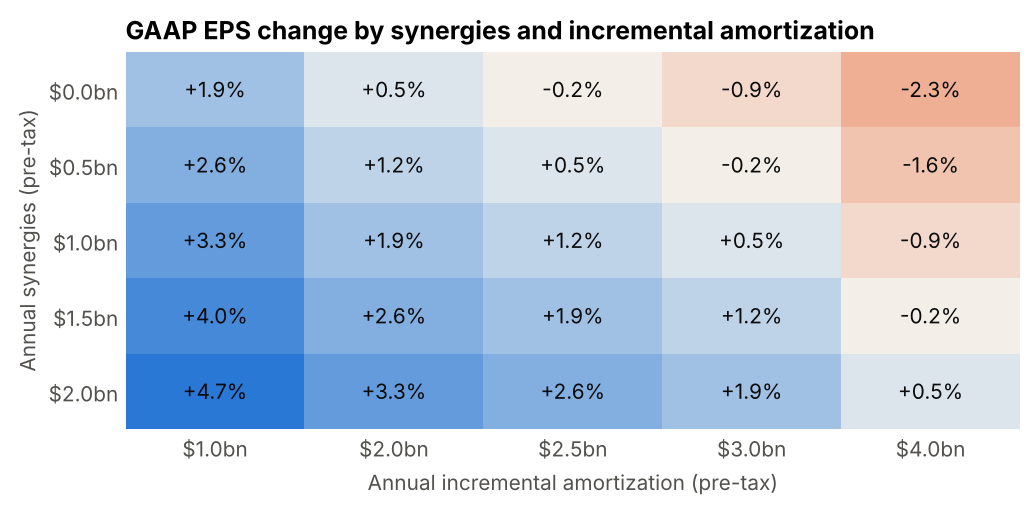

In [13]:
synergies = [0, 500, 1000, 1500, 2000]
amorts = [1000, 2000, 2500, 3000, 4000]
gaap_table = pd.DataFrame(
    [[dm.accretion(I["msft_net_income"], I["atvi_net_income"], msft_shares, cash_used, y_base, tax, s, a) * 100
      for a in amorts] for s in synergies],
    index=[f"${s / 1000:.1f}bn" for s in synergies], columns=[f"${a / 1000:.1f}bn" for a in amorts])
heatmap(gaap_table, "GAAP EPS change by synergies and incremental amortization",
        "Annual incremental amortization (pre-tax)", "Annual synergies (pre-tax)", "7_sensitivity_gaap")

## 6. Later comparison

These disclosures came after closing and were not available at announcement.

On its Q2 FY2024 earnings call, Microsoft said Activision reduced EPS by USD 0.05 in the quarter, including USD 1.1bn of purchase accounting, integration and transaction-related costs. It also expected Activision to add to FY2024 operating income once those costs were excluded.

The -USD 0.05 is consistent with the point that purchase accounting and integration costs matter, but it **does not validate** my annual estimate. It covers part of one quarter, includes one-off costs and reflects 2023 results rather than 2021 earnings.

The figures below give context for the USD 2.5bn assumption, which remains a separate, illustrative incremental charge over 2021 net income.

- **By-class estimate:** each intangible class divided by its weighted-average life, then added up. A single 15-year life cannot be used, because the classes have very different lives. This is an illustrative approximation, not a forecast of the amortization actually recognized, which need not be straight-line.
- **Microsoft's guidance:** about USD 700m for one quarter, in cost of revenue only. Annualizing it assumes every quarter is the same, and it leaves out any amortization recorded in operating expenses.

In [14]:
classes = pd.DataFrame({
    "Amount ($m)": [I[f"close_{k}_intangibles"] for k in ("marketing", "technology", "customer")],
    "Life (years)": [I[f"close_{k}_life"] for k in ("marketing", "technology", "customer")],
}, index=["Marketing-related", "Technology-based", "Customer-related"])
classes["Straight-line ($m a year)"] = classes["Amount ($m)"] / classes["Life (years)"]
print(classes.round(1).to_string())
print()
print(f"By-class straight-line estimate:               ${classes['Straight-line ($m a year)'].sum():,.0f}m a year")
print(f"Microsoft's quarterly guidance, annualized:    ${I['later_quarter_amortization'] * 4:,.0f}m a year (cost of revenue only)")
print(f"Incremental assumption in the EPS sensitivity: ${amort_base:,.0f}m a year")

                   Amount ($m)  Life (years)  Straight-line ($m a year)
Marketing-related      11619.0          24.0                      484.1
Technology-based        9689.0           4.0                     2422.2
Customer-related         661.0           4.0                      165.2

By-class straight-line estimate:               $3,072m a year
Microsoft's quarterly guidance, annualized:    $2,800m a year (cost of revenue only)
Incremental assumption in the EPS sensitivity: $2,500m a year


## Results at a glance

These are outputs of the model above, before interpretation.

In [15]:
base = result["Non-GAAP, no synergies"]
gaap = result["GAAP, incremental amortization"]
abnormal = f"{day0:+.2%} (t = {t0:.2f})" if MARKET_DATA else "NOT RUN, needs market data"
summary = pd.Series({
    "Premium to prior close": f"{dm.premium(offer, I['atvi_undisturbed']):.1%}",
    "Estimated diluted shares": f"{shares:.1f}m",
    "Bottom-up diluted shares": f"{bottom_up:.1f}m",
    "EV / Revenue at $95": f"{comps.loc['EV/Revenue', 'ATVI at $95']:.1f}x",
    "EV / Adjusted EBITDA at $95, policy": f"{comps.loc['EV/EBITDA', 'ATVI at $95']:.1f}x",
    "EV / Adjusted EBITDA at $95, alternative": f"{alternative['ATVI at $95']:.1f}x",
    "P/E at $95": f"{comps.loc['P/E', 'ATVI at $95']:.1f}x",
    "MSFT abnormal return, day 0": abnormal,
    "Binary-model implied probability, day 1": f"{dm.implied_completion_probability(I['atvi_day1_close'], offer, I['atvi_undisturbed']):.0%}",
    "Illustrative non-GAAP EPS change at 1% yield": f"{base['EPS change']:+.1%}",
    "Illustrative GAAP EPS change at 1% yield": f"{gaap['EPS change']:+.1%}",
    "Breakeven yield, non-GAAP": f"{base['Breakeven yield']:.1%}",
})
print(summary.to_string())

Premium to prior close                                       45.3%
Estimated diluted shares                                    794.9m
Bottom-up diluted shares                                    795.9m
EV / Revenue at $95                                           7.8x
EV / Adjusted EBITDA at $95, policy                          20.4x
EV / Adjusted EBITDA at $95, alternative                     18.6x
P/E at $95                                                   28.0x
MSFT abnormal return, day 0                     -0.37% (t = -0.42)
Binary-model implied probability, day 1                        57%
Illustrative non-GAAP EPS change at 1% yield                 +4.2%
Illustrative GAAP EPS change at 1% yield                     -0.2%
Breakeven yield, non-GAAP                                     4.9%


## My conclusions

**1. Price.** I think USD 95 was defensible, but I can't say it was cheap or that the deal created value. The 45.3% premium cost about USD 23.5bn on my share estimate, and 7.8x revenue is well above EA and Take-Two. Earnings give a different picture: the P/E of 28.0x is below both. Activision's 37% operating margin is more than double theirs, which helps explain why sales and earnings multiples point in different directions, although I can't show it is the cause. I don't rely much on EV/Adjusted EBITDA, because the comparison changes depending on how capitalized software is treated. With only two peers and dates that don't fully match, the most I would say is that the price doesn't look obviously excessive. The EPS result below doesn't change this. Whether the deal created value depends on cash flows, cost of capital and strategic benefits that I didn't model.

**2. Market reaction.** Microsoft's share price told me very little. The abnormal return on the day was small and not significant with any of the three benchmarks. That isn't surprising: the deal was about 3% of Microsoft's market value and large technology stocks were falling that day, so I can't isolate the effect of the deal. Activision is more informative, since it closed well below USD 95. My simple model turns that gap into about 57%, but I treat this as a sign that investors were cautious, not as the real chance of completion. It depends on the fallback price, and the gap also pays investors for waiting until closing. The deal needed regulatory review, which was probably part of that caution.

**3. EPS.** At a 1% yield on cash, non-GAAP EPS rises by 4.2% in my model, which fits Microsoft's statement that the deal would be accretive. With USD 2.5bn of extra amortization, GAAP EPS is about flat. The number I find most interesting is the 4.9% breakeven yield. The Fed's target range went from 0% to 0.25% in January 2022 to 5.25% to 5.50% by September 2023, so the wait for closing may have made the cash more expensive to give up. This is still a hypothesis, because I didn't measure what Microsoft earned on its cash or what Activision earned in 2023.

**4. Next steps.** I would add more peers and past deals, match prices and financials by date, use forecasts for the closing year and get full daily Activision prices from a licensed database. To test value creation properly, I would need a cash flow model with its own assumptions for cost of capital and synergies.